In [1]:
!pip -q install ultralytics pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.0 MB/s eta 0:00:00ta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.2/97.2 kB 3.3 MB/s eta 0:00:00


In [2]:
from ultralytics import YOLO
from pathlib import Path
import torch
import yaml
import pandas as pd
import matplotlib.pyplot as plt
import shutil

DEVICE = 0 if torch.cuda.is_available() else "cpu"
IMGSZ = 640  # Use the same resolution as RT-DETR

print("Device:", DEVICE)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Device: cpu


In [3]:
IMAGE_DIR = Path("/kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/images")
LABEL_DIR = Path("/kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/labels")
YAML_PATH = Path("/kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/data.yaml")

# Your C2A-finetuned YOLO11l checkpoint
MODEL_PATH = "/kaggle/input/datasets/ashrifrahmanarian/yolo11l-c2a-finetuned/yolo11L_flood_best.pt"

DATASET_ROOT = IMAGE_DIR.parent.parent

RESULTS_DIR = "/kaggle/working/YOLO11l_Results"

assert IMAGE_DIR.is_dir()
assert LABEL_DIR.is_dir()
assert Path(MODEL_PATH).is_file()

images = sorted([
    p for p in IMAGE_DIR.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
])

print("Images:", len(images))
print("Dataset root:", DATASET_ROOT)

Images: 27
Dataset root: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external


In [4]:
DATA_YAML = "/kaggle/working/yolo11l_external_test.yaml"

config = {
    "path": str(DATASET_ROOT),
    "train": str(IMAGE_DIR),
    "val": str(IMAGE_DIR),
    "test": str(IMAGE_DIR),
    "nc": 1,
    "names": {0: "human"}
}

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(open(DATA_YAML).read())

path: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external
train: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/images
val: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/images
test: /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/images
nc: 1
names:
  0: human



In [5]:
from ultralytics import YOLO

model = YOLO(MODEL_PATH)

print("Model type:", type(model.model).__name__)
print("Detection head:", type(model.model.model[-1]).__name__)
print("Number of classes:", len(model.names))
print("Person class:", model.names[0])

assert model.names[0] == "person", "Class 0 must represent person!"

Model type: DetectionModel
Detection head: Detect
Number of classes: 1
Person class: human


AssertionError: Class 0 must represent person!

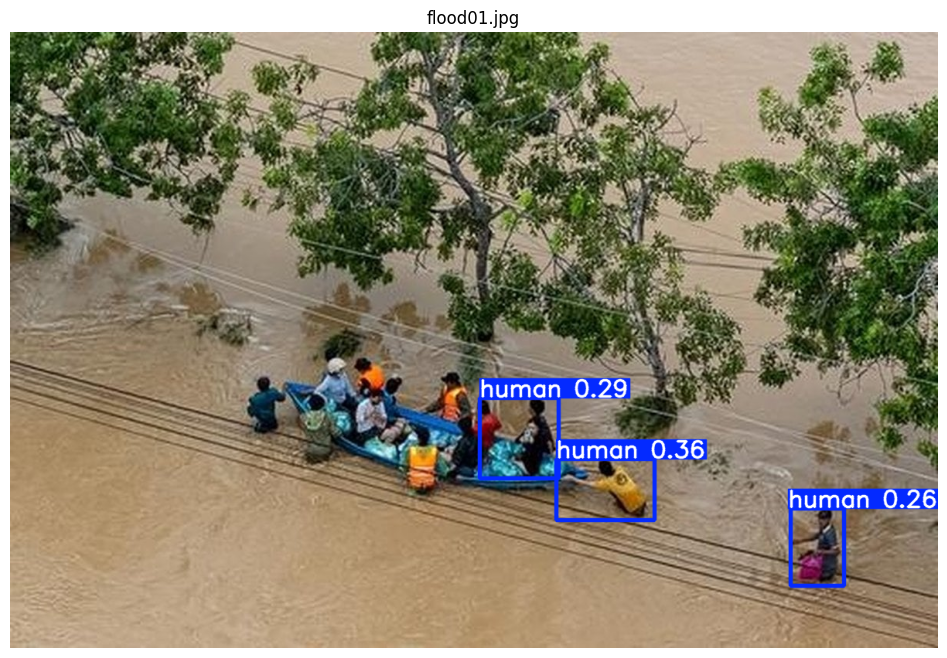

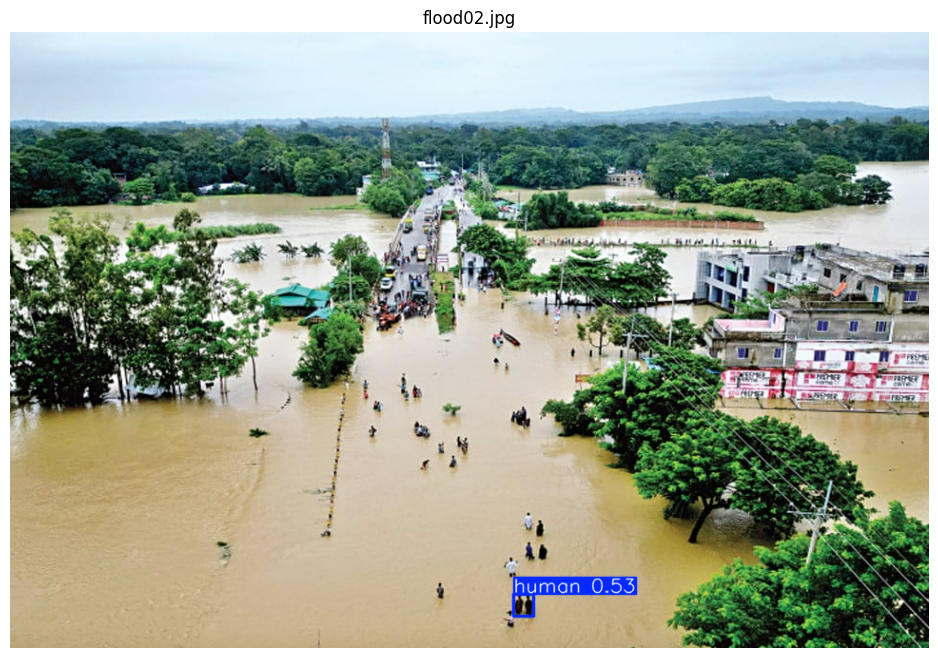

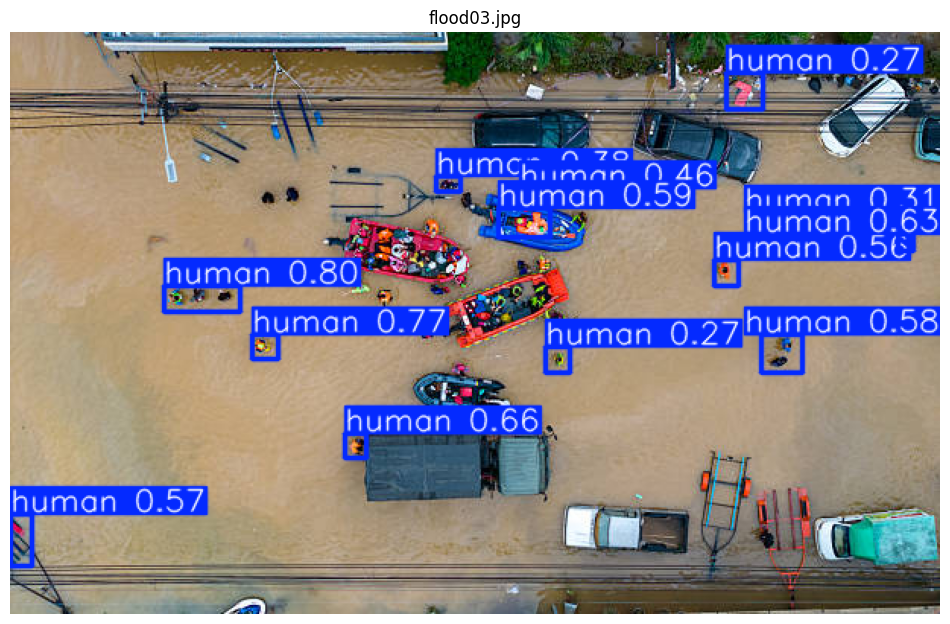

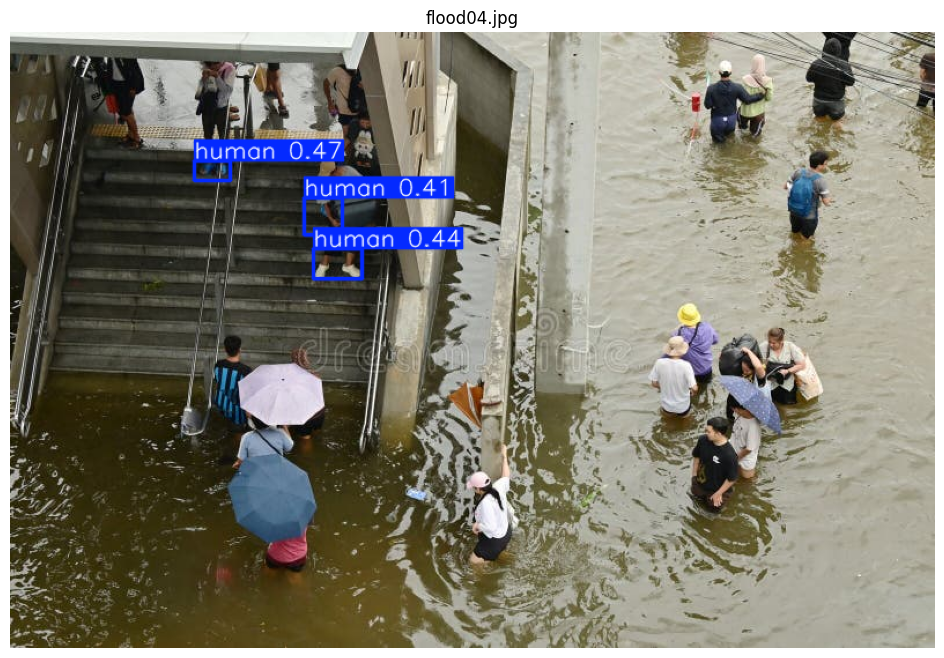

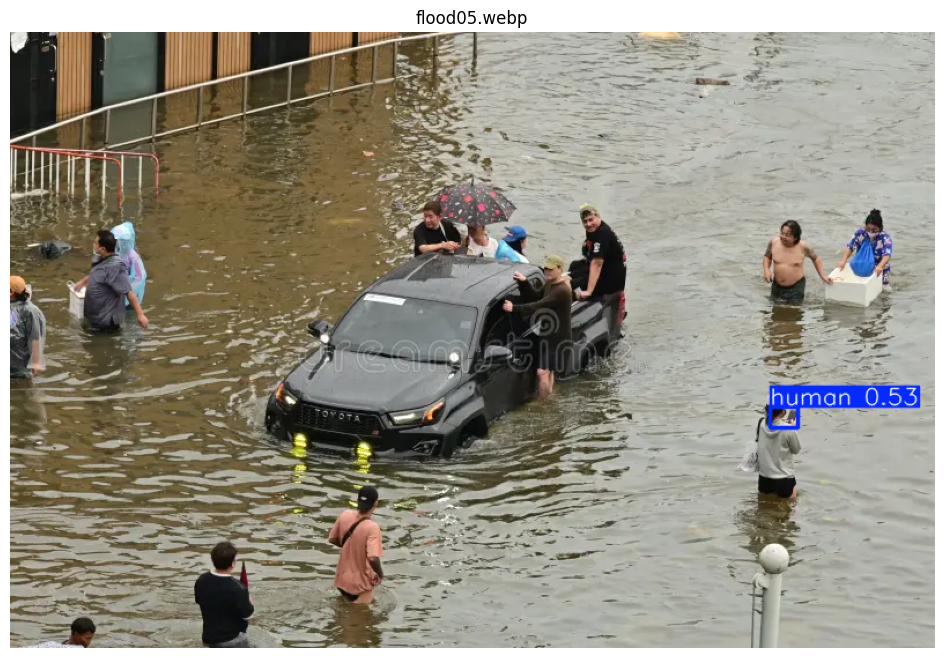

In [6]:
results = model.predict(
    source=[str(p) for p in images[:5]],
    imgsz=IMGSZ,
    conf=0.25,
    device=DEVICE,
    verbose=False
)

for result in results:
    plt.figure(figsize=(12, 8))
    plt.imshow(result.plot()[:, :, ::-1])
    plt.title(Path(result.path).name)
    plt.axis("off")
    plt.show()

In [7]:
predictions = model.predict(
    source=str(IMAGE_DIR),
    imgsz=IMGSZ,
    conf=0.25,
    device=DEVICE,
    save=True,
    save_txt=True,
    save_conf=True,
    project=RESULTS_DIR,
    name="predictions",
    exist_ok=True,
    verbose=False
)

print("Total images processed:", len(predictions))

Results saved to /kaggle/working/YOLO11l_Results/predictions
20 labels saved to /kaggle/working/YOLO11l_Results/predictions/labels
Total images processed: 27


In [8]:
metrics = model.val(
    data=DATA_YAML,
    split="test",
    imgsz=IMGSZ,
    batch=4,
    conf=0.001,
    device=DEVICE,
    plots=True,
    project=RESULTS_DIR,
    name="evaluation",
    exist_ok=True
)

precision = float(metrics.box.mp)
recall = float(metrics.box.mr)
map50 = float(metrics.box.map50)
map5095 = float(metrics.box.map)

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0.0
)

print(f"Precision:       {precision:.4f}")
print(f"Recall:          {recall:.4f}")
print(f"F1 (summary):    {f1:.4f}")
print(f"mAP@0.5:         {map50:.4f}")
print(f"mAP@0.5:0.95:    {map5095:.4f}")

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11l summary (fused): 190 layers, 25,280,083 parameters, 0 gradients, 86.8 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.4 ms, read: 392.7±64.9 MB/s, size: 293.2 KB)
val: Scanning /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external/labels... 27 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 27/27 453.0it/s 0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/ashrifrahmanarian/floodvictim-external/floodVictim_external is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 7/7 2.9s/it 20.6s3.4ss
                   all         27        288      0.212      0.181      0.098     0.0362
Speed: 0.7ms preprocess, 735.3ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to /kaggle/working/YOLO11l_Results/evaluation
Precision:       0.2123
Recall:          0.1806
F1 